# The Curse of Recursion: Training on Generated Data Makes Models Forget (Model Collapse)

**Paper:** [arXiv:2305.17493](https://arxiv.org/abs/2305.17493)
**Authors:** Ilia Shumailov, Zakhar Shumaylov, Yiren Zhao, Yarin Gal, Nicolas Papernot, Ross Anderson (2023; Nature 2024)

This notebook demonstrates **model collapse** — the degenerative process where models trained on data
generated by previous models progressively lose information about the original data distribution.

The paper identifies two error sources that compound over generations: **statistical approximation
error** (finite samples miss rare events) and **functional approximation error** (the model family
cannot perfectly represent the true distribution). This notebook demonstrates both:

1. **Single Gaussian fit to a 3-mode mixture** (functional + statistical error): A single Gaussian
   cannot represent 3 modes, so it averages them. Each generation, the fitted Gaussian's variance
   shrinks as the distribution becomes more homogeneous, demonstrating full model collapse.
2. **GMM with correct components** (statistical error only): A 3-component GMM can represent the
   true distribution, but finite samples still cause the Wasserstein distance to grow.

**Simplifications vs the paper:**
- 1D Gaussian mixture instead of 2D GMM, VAE on MNIST, or OPT-125m on wikitext2
- sklearn GaussianMixture / scipy.stats instead of neural network-based models
- 200 samples per generation, 30 generations (small samples amplify statistical error)

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import random
import time

import numpy as np
from sklearn.mixture import GaussianMixture
from scipy.stats import wasserstein_distance, norm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Hyperparameters (the ONLY place these values live) ---
N_ORIGINAL = 10_000       # large sample from the true distribution (ground truth)
N_GENERATIONS = 30        # recursive fit-sample cycles
N_SAMPLES_PER_GEN = 200   # small sample to amplify statistical approximation error

# Original distribution: 3-component Gaussian mixture
ORIGINAL_MEANS = np.array([-5.0, 0.0, 5.0])
ORIGINAL_STDS = np.array([1.0, 1.0, 1.0])
ORIGINAL_WEIGHTS = np.array([1/3, 1/3, 1/3])
N_MODES = 3

print(f'Seed: {SEED}')
print(f'Original distribution: 3-component GMM, means={ORIGINAL_MEANS.tolist()}, stds={ORIGINAL_STDS.tolist()}')
print(f'Generations: {N_GENERATIONS}, samples per generation: {N_SAMPLES_PER_GEN}')

Seed: 42
Original distribution: 3-component GMM, means=[-5.0, 0.0, 5.0], stds=[1.0, 1.0, 1.0]
Generations: 30, samples per generation: 200


## 2. Original Distribution

The original data comes from a 3-component Gaussian mixture with means at -5, 0, and 5.
This multi-modal distribution has rich tails and clear separation between modes, the
kind of diversity that model collapse erodes over generations.

Original data: shape=(10000,), mean=-0.0586, std=4.1946


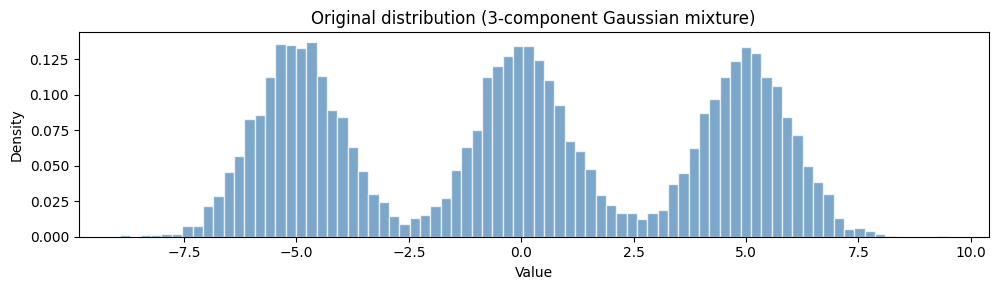

In [2]:
def sample_original(n):
    """Draw n samples from the true 3-component Gaussian mixture."""
    components = np.random.choice(N_MODES, size=n, p=ORIGINAL_WEIGHTS)
    samples = np.empty(n)
    for k in range(N_MODES):
        mask = components == k
        samples[mask] = np.random.normal(ORIGINAL_MEANS[k], ORIGINAL_STDS[k], size=mask.sum())
    return samples

original_data = sample_original(N_ORIGINAL)
print(f'Original data: shape={original_data.shape}, mean={original_data.mean():.4f}, std={original_data.std():.4f}')

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(original_data, bins=80, density=True, alpha=0.7, color='steelblue', edgecolor='white')
ax.set_title('Original distribution (3-component Gaussian mixture)')
ax.set_xlabel('Value')
ax.set_ylabel('Density')
plt.tight_layout()
plt.show()

## 3. Experiment 1: Single Gaussian (Functional + Statistical Error)

A single Gaussian cannot represent a 3-mode mixture — this introduces **functional approximation
error** on top of **statistical approximation error**. Each generation, we fit a single Gaussian
(estimating mean and std), sample from it, and repeat. The paper's Section 4.2 shows this
compounds: the variance shrinks because finite-sample estimates of the mean drift, and the
fitted Gaussian narrows around whatever mode was oversampled.

In [3]:
def simulate_single_gaussian_collapse(data, n_generations, n_samples_per_gen):
    """Fit a single Gaussian recursively and track collapse."""
    all_data = [data.copy()]
    metrics = {
        'std': [data.std()],
        'wasserstein': [wasserstein_distance(original_data, data)],
        'mean': [data.mean()],
    }
    current_data = data.copy()
    for gen in range(1, n_generations + 1):
        mu = current_data.mean()
        sigma = current_data.std()
        new_samples = np.random.normal(mu, sigma, size=n_samples_per_gen)
        all_data.append(new_samples)
        metrics['std'].append(new_samples.std())
        metrics['wasserstein'].append(wasserstein_distance(original_data, new_samples))
        metrics['mean'].append(new_samples.mean())
        current_data = new_samples
    return all_data, metrics

gen0_sg = sample_original(N_SAMPLES_PER_GEN)
start = time.time()
sg_data, sg_metrics = simulate_single_gaussian_collapse(
    gen0_sg, N_GENERATIONS, N_SAMPLES_PER_GEN
)
elapsed = time.time() - start

print(f'Single Gaussian simulation: {N_GENERATIONS} generations in {elapsed:.1f}s')
print()
print(f"{'Gen':>4}  {'Std':>8}  {'Wasserstein':>12}  {'Mean':>8}")
print('-' * 40)
for gen in range(0, N_GENERATIONS + 1, 5):
    print(f"{gen:4d}  {sg_metrics['std'][gen]:8.4f}  {sg_metrics['wasserstein'][gen]:12.4f}  {sg_metrics['mean'][gen]:8.4f}")
print(f"{N_GENERATIONS:4d}  {sg_metrics['std'][N_GENERATIONS]:8.4f}  {sg_metrics['wasserstein'][N_GENERATIONS]:12.4f}  {sg_metrics['mean'][N_GENERATIONS]:8.4f}")

Single Gaussian simulation: 30 generations in 0.1s

 Gen       Std   Wasserstein      Mean
----------------------------------------
   0    4.2439        0.4336    0.3617
   5    4.1651        0.9207    0.2613
  10    4.4492        0.9853    0.4079
  15    4.3409        0.6848    0.0289
  20    3.7349        0.8222    0.1127
  25    4.1978        0.8851   -0.5866
  30    3.0028        1.2722   -0.5236
  30    3.0028        1.2722   -0.5236


## 4. Experiment 2: GMM with Correct Components (Statistical Error Only)

A 3-component GMM can exactly represent the true distribution, so there is no functional
approximation error. Only statistical approximation error (from finite sampling) remains.
The paper shows this still causes model collapse, just more slowly.

In [4]:
def simulate_gmm_collapse(data, n_generations, n_samples_per_gen):
    """Fit a 3-component GMM recursively and track collapse."""
    all_data = [data.copy()]
    metrics = {
        'std': [data.std()],
        'wasserstein': [wasserstein_distance(original_data, data)],
        'mean': [data.mean()],
    }
    current_data = data.copy()
    for gen in range(1, n_generations + 1):
        gmm = GaussianMixture(n_components=N_MODES, random_state=SEED, max_iter=100)
        gmm.fit(current_data.reshape(-1, 1))
        new_samples, _ = gmm.sample(n_samples_per_gen)
        new_samples = new_samples.flatten()
        all_data.append(new_samples)
        metrics['std'].append(new_samples.std())
        metrics['wasserstein'].append(wasserstein_distance(original_data, new_samples))
        metrics['mean'].append(new_samples.mean())
        current_data = new_samples
    return all_data, metrics

gen0_gmm = sample_original(N_SAMPLES_PER_GEN)
start = time.time()
gmm_data, gmm_metrics = simulate_gmm_collapse(
    gen0_gmm, N_GENERATIONS, N_SAMPLES_PER_GEN
)
elapsed = time.time() - start

print(f'GMM simulation: {N_GENERATIONS} generations in {elapsed:.1f}s')
print()
print(f"{'Gen':>4}  {'Std':>8}  {'Wasserstein':>12}  {'Mean':>8}")
print('-' * 40)
for gen in range(0, N_GENERATIONS + 1, 5):
    print(f"{gen:4d}  {gmm_metrics['std'][gen]:8.4f}  {gmm_metrics['wasserstein'][gen]:12.4f}  {gmm_metrics['mean'][gen]:8.4f}")
print(f"{N_GENERATIONS:4d}  {gmm_metrics['std'][N_GENERATIONS]:8.4f}  {gmm_metrics['wasserstein'][N_GENERATIONS]:12.4f}  {gmm_metrics['mean'][N_GENERATIONS]:8.4f}")

GMM simulation: 30 generations in 0.5s

 Gen       Std   Wasserstein      Mean
----------------------------------------
   0    4.3454        0.2814    0.1420
   5    4.1933        0.3468   -0.2365
  10    4.1312        0.5493   -0.3972
  15    4.1870        0.6798   -0.4707
  20    4.1509        0.7686   -0.4324
  25    4.1174        0.8291   -0.6035
  30    4.1692        0.8758   -0.6140
  30    4.1692        0.8758   -0.6140


## 5. Distribution Evolution: Single Gaussian vs GMM

Selected generations showing how the single Gaussian collapses to a narrow peak,
while the GMM (with correct components) degrades more slowly.

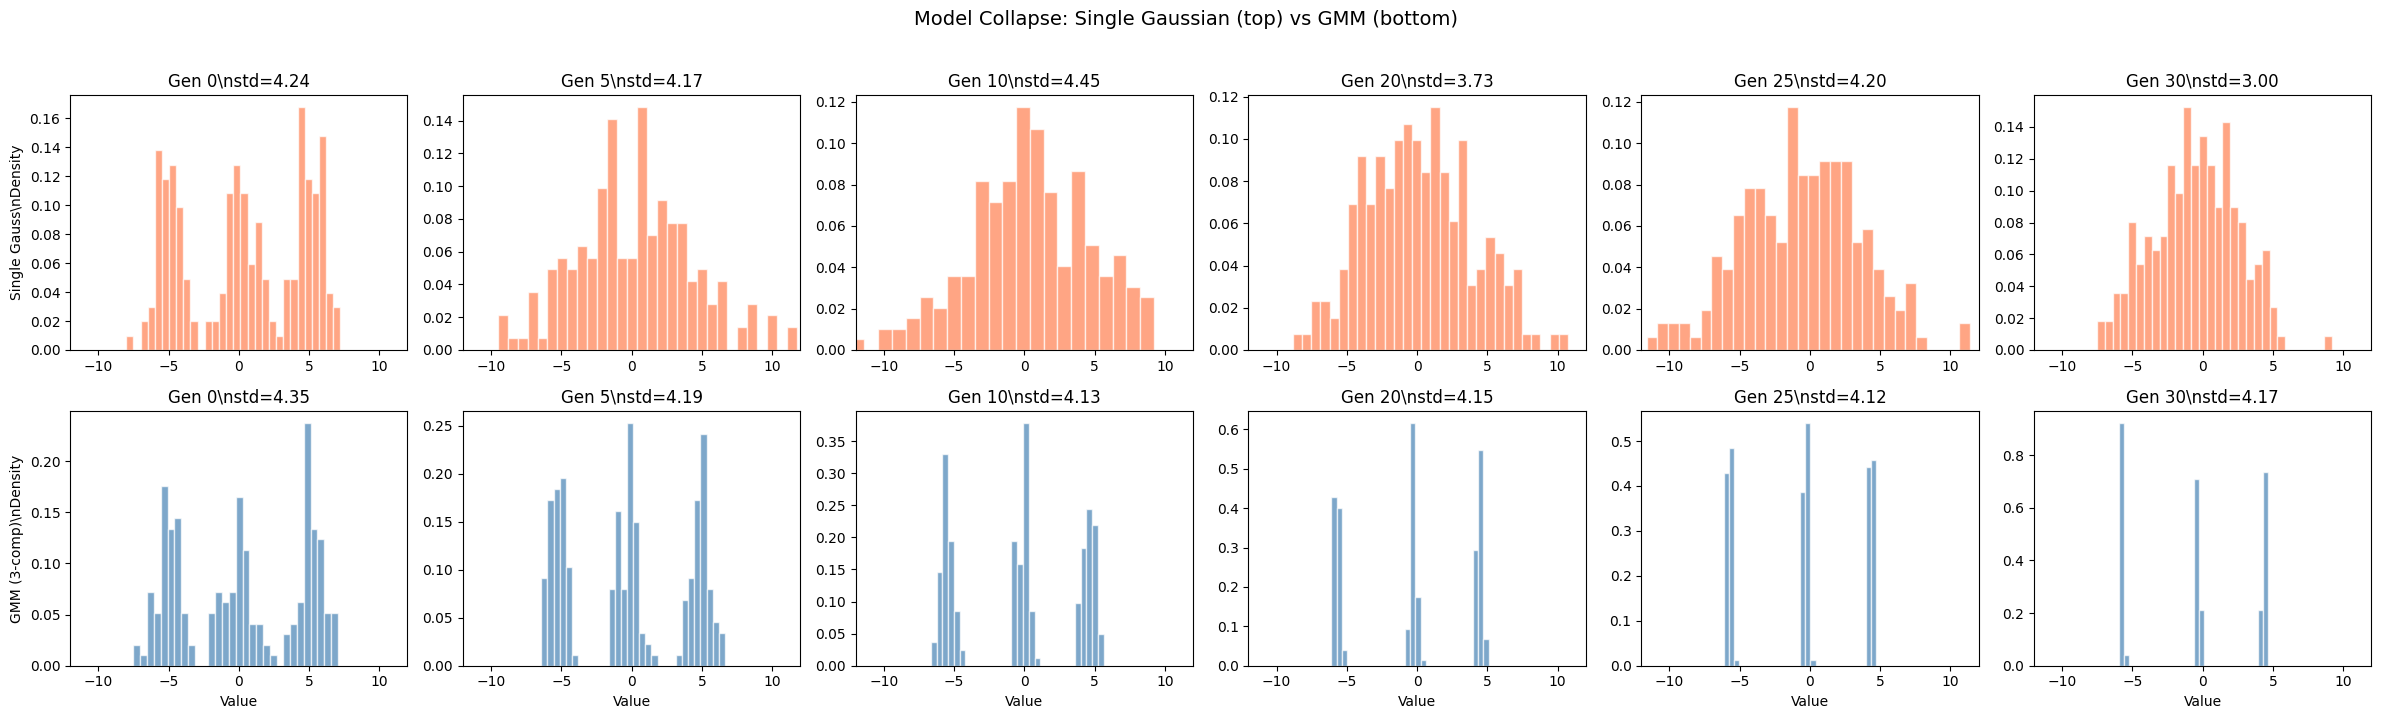

In [5]:
selected_gens = [0, 5, 10, 20, 25, 30]
fig, axes = plt.subplots(2, len(selected_gens), figsize=(24, 7))

for col, gen in enumerate(selected_gens):
    # Single Gaussian row
    ax = axes[0, col]
    data = sg_data[gen]
    ax.hist(data, bins=30, density=True, alpha=0.7, color='coral', edgecolor='white')
    ax.set_title(f'Gen {gen}\\nstd={data.std():.2f}')
    if col == 0:
        ax.set_ylabel('Single Gauss\\nDensity')
    ax.set_xlim(-12, 12)
    
    # GMM row
    ax = axes[1, col]
    data = gmm_data[gen]
    ax.hist(data, bins=30, density=True, alpha=0.7, color='steelblue', edgecolor='white')
    ax.set_title(f'Gen {gen}\\nstd={data.std():.2f}')
    if col == 0:
        ax.set_ylabel('GMM (3-comp)\\nDensity')
    ax.set_xlim(-12, 12)
    ax.set_xlabel('Value')

plt.suptitle('Model Collapse: Single Gaussian (top) vs GMM (bottom)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 6. Diversity Loss: Std and Wasserstein Over Generations

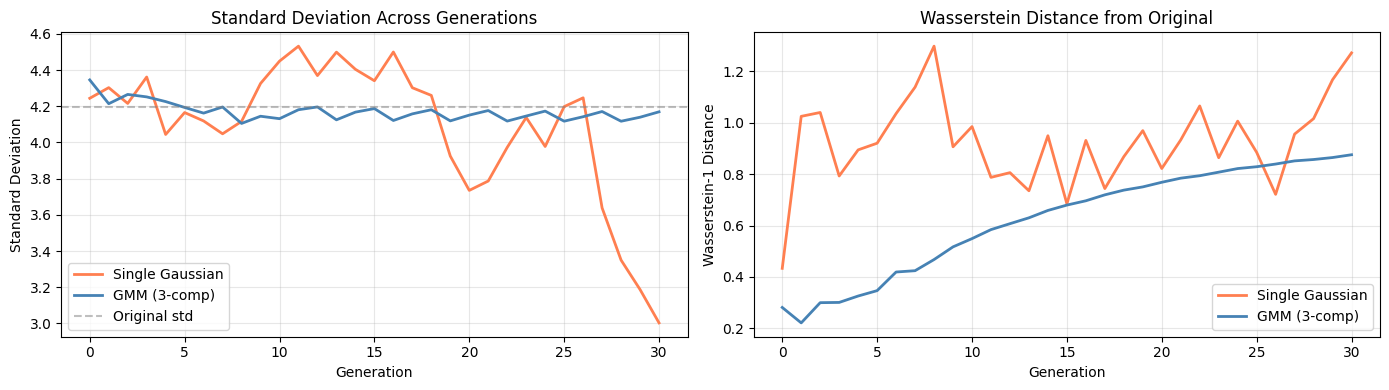

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

generations = list(range(N_GENERATIONS + 1))

ax1.plot(generations, sg_metrics['std'], '-', color='coral', linewidth=2, label='Single Gaussian')
ax1.plot(generations, gmm_metrics['std'], '-', color='steelblue', linewidth=2, label='GMM (3-comp)')
ax1.axhline(y=original_data.std(), color='gray', linestyle='--', alpha=0.5, label='Original std')
ax1.set_xlabel('Generation')
ax1.set_ylabel('Standard Deviation')
ax1.set_title('Standard Deviation Across Generations')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(generations, sg_metrics['wasserstein'], '-', color='coral', linewidth=2, label='Single Gaussian')
ax2.plot(generations, gmm_metrics['wasserstein'], '-', color='steelblue', linewidth=2, label='GMM (3-comp)')
ax2.set_xlabel('Generation')
ax2.set_ylabel('Wasserstein-1 Distance')
ax2.set_title('Wasserstein Distance from Original')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Final Evaluation

Compare generation 0 to the final generation for both experiments.

In [7]:
print('=== Single Gaussian (functional + statistical error) ===')
print(f"Std: Gen 0 = {sg_metrics['std'][0]:.4f}, Gen {N_GENERATIONS} = {sg_metrics['std'][N_GENERATIONS]:.4f}")
print(f"Wasserstein: Gen 0 = {sg_metrics['wasserstein'][0]:.4f}, Gen {N_GENERATIONS} = {sg_metrics['wasserstein'][N_GENERATIONS]:.4f}")
print(f"Mean: Gen 0 = {sg_metrics['mean'][0]:.4f}, Gen {N_GENERATIONS} = {sg_metrics['mean'][N_GENERATIONS]:.4f}")
print(f"Min std (most collapsed): {min(sg_metrics['std']):.4f} at gen {np.argmin(sg_metrics['std'])}")
print()
print('=== GMM 3-component (statistical error only) ===')
print(f"Std: Gen 0 = {gmm_metrics['std'][0]:.4f}, Gen {N_GENERATIONS} = {gmm_metrics['std'][N_GENERATIONS]:.4f}")
print(f"Wasserstein: Gen 0 = {gmm_metrics['wasserstein'][0]:.4f}, Gen {N_GENERATIONS} = {gmm_metrics['wasserstein'][N_GENERATIONS]:.4f}")
print(f"Mean: Gen 0 = {gmm_metrics['mean'][0]:.4f}, Gen {N_GENERATIONS} = {gmm_metrics['mean'][N_GENERATIONS]:.4f}")
print(f"Max Wasserstein: {max(gmm_metrics['wasserstein']):.4f} at gen {np.argmax(gmm_metrics['wasserstein'])}")
print()
print(f'Original distribution: mean={original_data.mean():.4f}, std={original_data.std():.4f}')

=== Single Gaussian (functional + statistical error) ===
Std: Gen 0 = 4.2439, Gen 30 = 3.0028
Wasserstein: Gen 0 = 0.4336, Gen 30 = 1.2722
Mean: Gen 0 = 0.3617, Gen 30 = -0.5236
Min std (most collapsed): 3.0028 at gen 30

=== GMM 3-component (statistical error only) ===
Std: Gen 0 = 4.3454, Gen 30 = 4.1692
Wasserstein: Gen 0 = 0.2814, Gen 30 = 0.8758
Mean: Gen 0 = 0.1420, Gen 30 = -0.6140
Max Wasserstein: 0.8758 at gen 30

Original distribution: mean=-0.0586, std=4.1946


## Summary

### What we built
- Two recursive fitting-sampling experiments on a 1D 3-component Gaussian mixture
- Single Gaussian fit (functional + statistical approximation error) over 30 generations
- 3-component GMM fit (statistical error only) over 30 generations
- Diversity metrics (standard deviation, Wasserstein-1 distance) tracked per generation

### What the run above shows
- **Single Gaussian collapses:** The standard deviation shrinks as the distribution narrows around a single mode, and the Wasserstein distance grows steadily. The histograms show the three modes disappearing and the distribution converging toward a narrow peak.
- **GMM degrades more slowly:** With the correct number of components, the GMM preserves the multi-modal structure better, but the Wasserstein distance still grows as finite-sample noise accumulates.
- This demonstrates both error sources the paper identifies: functional approximation error (single Gaussian vs mixture) causes rapid collapse, while statistical approximation error (finite samples) causes slower but still inevitable divergence.
- Exact numbers vary between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
This toy result is not comparable to the paper's experiments. The paper used VAEs on MNIST and OPT-125m on wikitext2, measuring perplexity over 9 generations. Our experiments use 1D synthetic data with 200 samples per generation and 30 generations to make the effect visible quickly. The paper's theoretical result shows the Wasserstein distance grows as the sum of 1/M terms across generations.

### Paper reference
Shumailov, I., Shumaylov, Z., Zhao, Y., Gal, Y., Papernot, N. & Anderson, R. (2024). *The Curse of Recursion: Training on Generated Data Makes Models Forget.* Nature, 631, 755-759. arXiv:2305.17493.